# ENEM 2020: visões sobre as notas

Este notebook lê o modelo dimensional carregado no MySQL e gera as visões pedidas no teste. Cada gráfico é salvo em `docs/img/` e aparece no README.

- **Nota como indicador**: a média das quatro provas objetivas por participante (ADR-0006), só para quem esteve presente nas quatro.
- **Agregações** (médias por grupo) usam a população inteira, calculada em SQL.
- **Distribuições e correlações** usam uma amostra determinística de cerca de 10% dos participantes presentes nas quatro provas (`CRC32(nu_inscricao) % 10 = 0`). A amostra é a mesma a cada execução.

Para executar: `docker compose run --rm app jupyter nbconvert --to notebook --execute --inplace notebooks/analise_enem_2020.ipynb`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.etl.load import conectar  # noqa: E402

PASTA_IMG = RAIZ / "docs" / "img"
PASTA_IMG.mkdir(parents=True, exist_ok=True)

# Paleta e tinta validadas para leitura com daltonismo (fundo claro)
SUPERFICIE = "#fcfcfb"
TINTA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
TINTA_SUAVE = "#898781"
GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # azul, laranja, aqua, amarelo
AZUL = SERIES[0]
DIVERGENTE = LinearSegmentedColormap.from_list(
    "divergente", ["#e34948", "#f0efec", "#2a78d6"]
)  # vermelho (negativo), cinza neutro, azul (positivo)

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE, "figure.dpi": 110, "savefig.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TINTA, "axes.labelcolor": TINTA_SECUNDARIA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 24,  # espaço para o subtítulo entre o título e o gráfico
    "axes.titlecolor": TINTA, "axes.edgecolor": EIXO,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "xtick.labelcolor": TINTA_SECUNDARIA, "ytick.labelcolor": TINTA_SECUNDARIA,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2,
})


def consultar(sql: str) -> pd.DataFrame:
    """Executa uma consulta no MySQL e devolve um DataFrame."""
    conexao = conectar()
    try:
        with conexao.cursor() as cursor:
            cursor.execute(sql)
            colunas = [c[0] for c in cursor.description]
            df = pd.DataFrame(cursor.fetchall(), columns=colunas)
    finally:
        conexao.close()
    # Decimal do MySQL vira float para os cálculos
    for coluna in df.columns:
        if df[coluna].dtype == object and len(df) and type(df[coluna].iloc[0]).__name__ == "Decimal":
            df[coluna] = df[coluna].astype(float)
    return df


def num(valor: float, casas: int = 1) -> str:
    """Formata número no padrão brasileiro (vírgula decimal, ponto de milhar)."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def salvar(fig, nome: str) -> None:
    """Salva o gráfico em docs/img com margens ajustadas."""
    fig.tight_layout()
    fig.savefig(PASTA_IMG / f"{nome}.png", bbox_inches="tight", pad_inches=0.25)
    plt.show()


def subtitulo(ax, texto: str) -> None:
    """Escreve uma linha de contexto abaixo do título do gráfico."""
    ax.text(0, 1.015, texto, transform=ax.transAxes, color=TINTA_SECUNDARIA, fontsize=9, va="bottom")


PROVAS = {"nu_nota_cn": "Ciências da Natureza", "nu_nota_ch": "Ciências Humanas",
          "nu_nota_lc": "Linguagens e Códigos", "nu_nota_mt": "Matemática"}

In [2]:
amostra = consultar("""
    SELECT f.nu_nota_cn, f.nu_nota_ch, f.nu_nota_lc, f.nu_nota_mt, f.nu_nota_redacao,
           f.nu_nota_comp1, f.nu_nota_comp2, f.nu_nota_comp3, f.nu_nota_comp4, f.nu_nota_comp5,
           f.nu_media_objetivas AS media, f.tp_status_redacao,
           p.tp_faixa_etaria, p.ds_sexo, p.ds_cor_raca, p.ds_escola, p.ds_treineiro,
           e.ds_dependencia_adm_esc, e.ds_localizacao_esc, l.sg_uf_prova,
           q.q001, q.q002, q.q005, q.q006, q.q008, q.q010, q.q024, q.q025
    FROM fato_participacao f
    JOIN dim_perfil p ON p.sk_perfil = f.sk_perfil
    JOIN dim_escola e ON e.sk_escola = f.sk_escola
    JOIN dim_local_prova l ON l.sk_local_prova = f.sk_local_prova
    JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL
      AND CRC32(f.nu_inscricao) % 10 = 0
""")
print(f"Amostra: {len(amostra):,} participantes presentes nas quatro provas")

Amostra: 258,587 participantes presentes nas quatro provas


## 1. A nota como indicador de desempenho

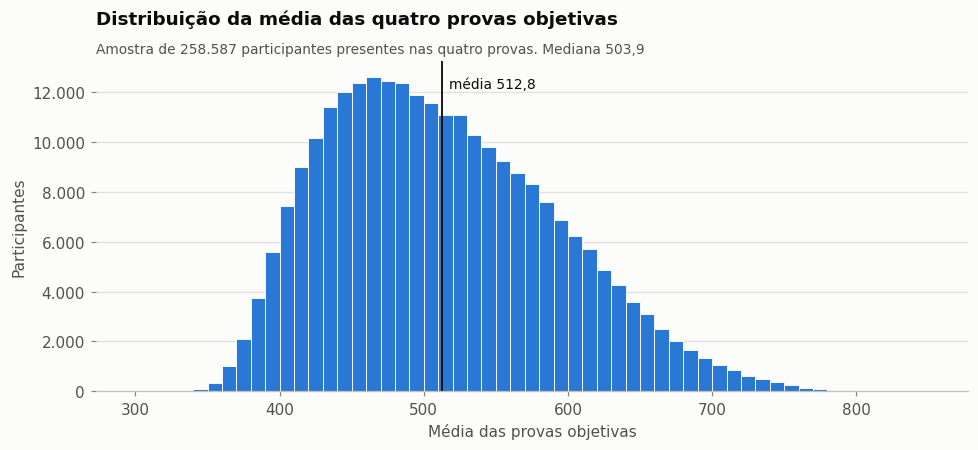

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(amostra["media"], bins=np.arange(300, 860, 10), color=AZUL, edgecolor=SUPERFICIE, linewidth=0.6)
media_geral = amostra["media"].mean()
mediana = amostra["media"].median()
ax.axvline(media_geral, color=TINTA, linewidth=1.2)
ax.text(media_geral + 5, ax.get_ylim()[1] * 0.92, f"média {num(media_geral)}", color=TINTA, fontsize=9)
ax.set_title("Distribuição da média das quatro provas objetivas")
subtitulo(ax, f"Amostra de {num(len(amostra), 0)} participantes presentes nas quatro provas. Mediana {num(mediana)}")
ax.set_xlabel("Média das provas objetivas")
ax.set_ylabel("Participantes")
ax.yaxis.set_major_formatter(lambda v, _: num(v, 0))
salvar(fig, "01_distribuicao_media")

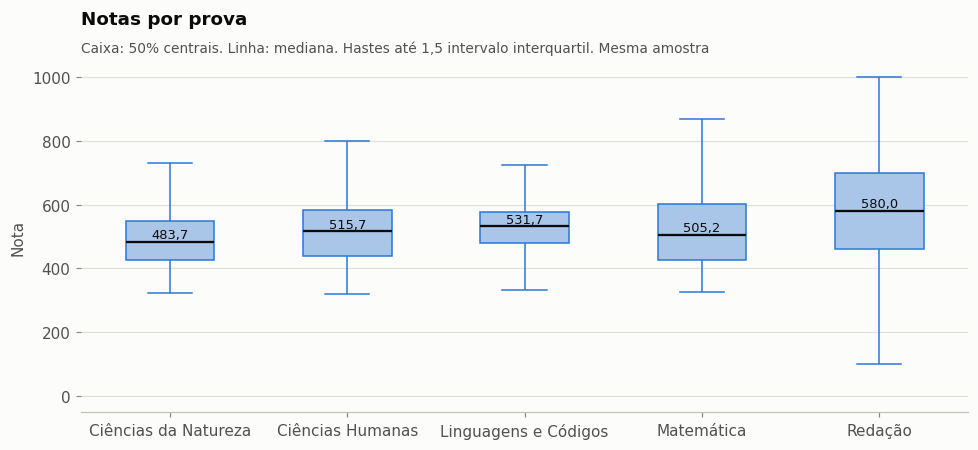

In [4]:
longo = amostra.melt(value_vars=list(PROVAS) + ["nu_nota_redacao"], var_name="prova", value_name="nota")
longo["prova"] = longo["prova"].map({**PROVAS, "nu_nota_redacao": "Redação"})
ordem = ["Ciências da Natureza", "Ciências Humanas", "Linguagens e Códigos", "Matemática", "Redação"]
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.boxplot(data=longo, x="prova", y="nota", order=ordem, color="#9ec5f4", width=0.5, fliersize=0,
            linewidth=1, medianprops={"color": TINTA, "linewidth": 1.5},
            boxprops={"edgecolor": AZUL}, whiskerprops={"color": AZUL}, capprops={"color": AZUL}, ax=ax)
for i, prova in enumerate(ordem):
    ax.text(i, longo.loc[longo["prova"] == prova, "nota"].median() + 12,
            num(longo.loc[longo["prova"] == prova, "nota"].median()), ha="center", fontsize=8.5, color=TINTA)
ax.set_title("Notas por prova")
subtitulo(ax, "Caixa: 50% centrais. Linha: mediana. Hastes até 1,5 intervalo interquartil. Mesma amostra")
ax.set_xlabel("")
ax.set_ylabel("Nota")
salvar(fig, "02_notas_por_prova")

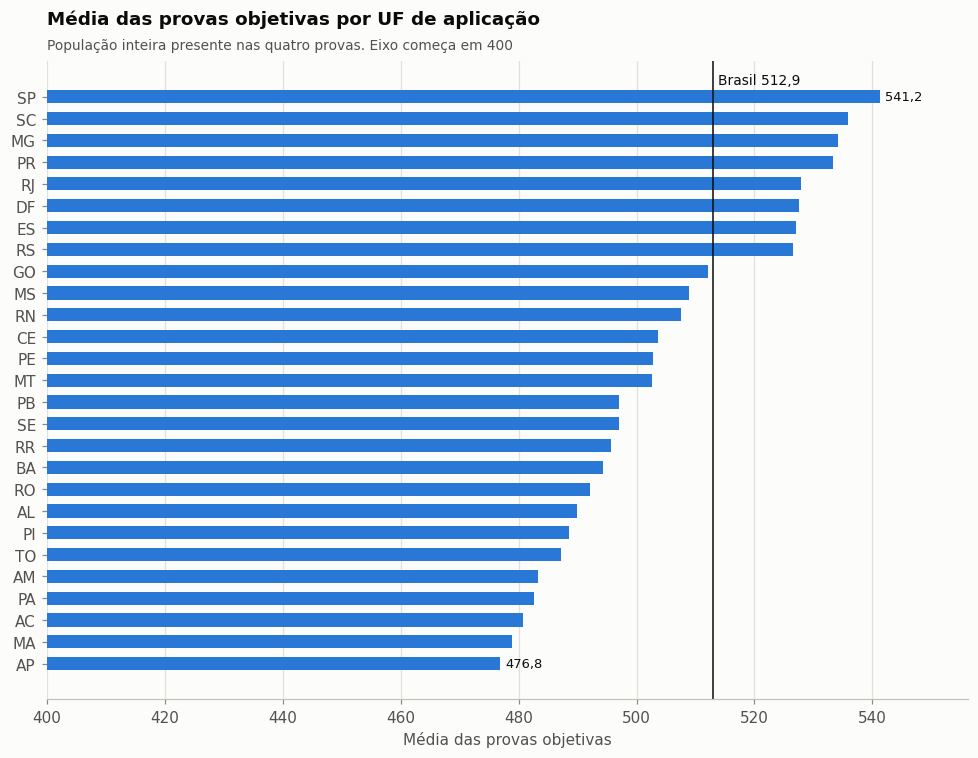

In [5]:
por_uf = consultar("""
    SELECT l.sg_uf_prova AS uf, COUNT(*) AS participantes, AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f JOIN dim_local_prova l ON l.sk_local_prova = f.sk_local_prova
    WHERE f.nu_media_objetivas IS NOT NULL
    GROUP BY l.sg_uf_prova ORDER BY media
""")
geral = consultar("SELECT AVG(nu_media_objetivas) AS media FROM fato_participacao")["media"].iloc[0]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(por_uf["uf"], por_uf["media"] - 400, left=400, color=AZUL, height=0.6)
ax.axvline(geral, color=TINTA, linewidth=1)
ax.text(geral + 1, len(por_uf) - 0.4, f"Brasil {num(geral)}", fontsize=9, color=TINTA)
for i, (uf, media) in enumerate(zip(por_uf["uf"], por_uf["media"])):
    if i in (0, len(por_uf) - 1):
        ax.text(media + 1, i, num(media), va="center", fontsize=8.5, color=TINTA)
ax.set_xlim(400, por_uf["media"].max() + 15)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Média das provas objetivas por UF de aplicação")
subtitulo(ax, "População inteira presente nas quatro provas. Eixo começa em 400")
ax.set_xlabel("Média das provas objetivas")
salvar(fig, "03_media_por_uf")

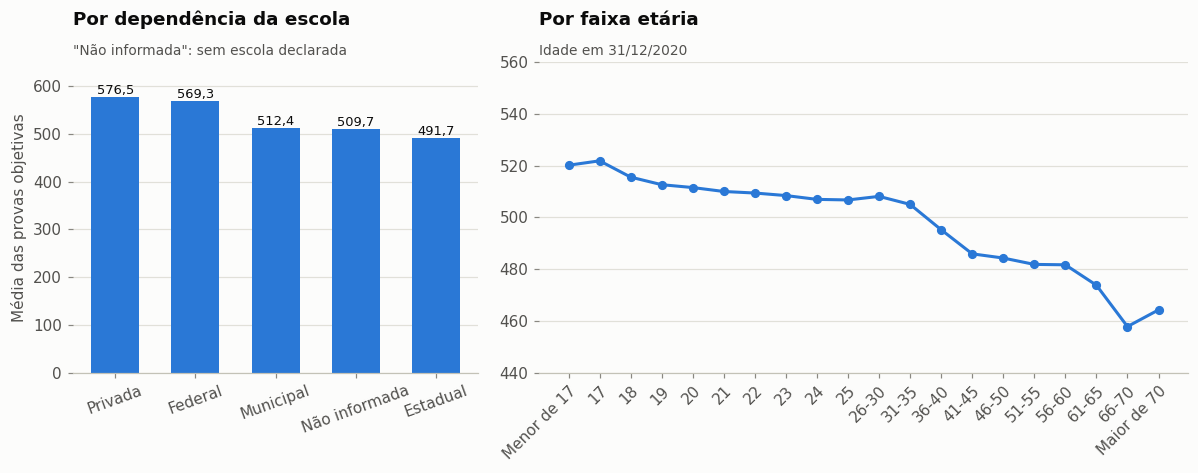

In [6]:
por_dependencia = consultar("""
    SELECT e.ds_dependencia_adm_esc AS dependencia, COUNT(*) AS participantes,
           AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f JOIN dim_escola e ON e.sk_escola = f.sk_escola
    WHERE f.nu_media_objetivas IS NOT NULL
    GROUP BY e.ds_dependencia_adm_esc ORDER BY media DESC
""")
por_faixa = consultar("""
    SELECT p.tp_faixa_etaria, p.ds_faixa_etaria AS faixa, COUNT(*) AS participantes,
           AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f JOIN dim_perfil p ON p.sk_perfil = f.sk_perfil
    WHERE f.nu_media_objetivas IS NOT NULL AND p.tp_faixa_etaria > 0
    GROUP BY p.tp_faixa_etaria, p.ds_faixa_etaria ORDER BY p.tp_faixa_etaria
""")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
ax1.bar(por_dependencia["dependencia"], por_dependencia["media"], color=AZUL, width=0.6)
for i, linha in por_dependencia.iterrows():
    ax1.text(i, linha["media"] + 6, num(linha["media"]), ha="center", fontsize=8.5, color=TINTA)
ax1.set_title("Por dependência da escola")
subtitulo(ax1, "\"Não informada\": sem escola declarada")
ax1.set_ylim(0, 650)
ax1.set_ylabel("Média das provas objetivas")
ax1.tick_params(axis="x", labelrotation=20)
rotulos = por_faixa["faixa"].str.replace("Entre ", "").str.replace(" anos", "").str.replace(" e ", "-")
ax2.plot(rotulos, por_faixa["media"], color=AZUL, marker="o", markersize=5)
ax2.set_title("Por faixa etária")
subtitulo(ax2, "Idade em 31/12/2020")
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax2.set_ylim(440, 560)
salvar(fig, "04_media_dependencia_faixa")

## 2. Correlação das variáveis com as notas

Spearman mede associação monotônica e serve para variáveis ordinais, como faixa de renda e escolaridade. As respostas "Não sei" (H em Q001 e Q002) ficam de fora. Para variáveis sem ordem (sexo, cor/raça, UF), a medida é o eta², a fração da variância da média explicada pelo grupo. A renda entra no gráfico de eta² como referência de comparação, mesmo sendo ordinal.

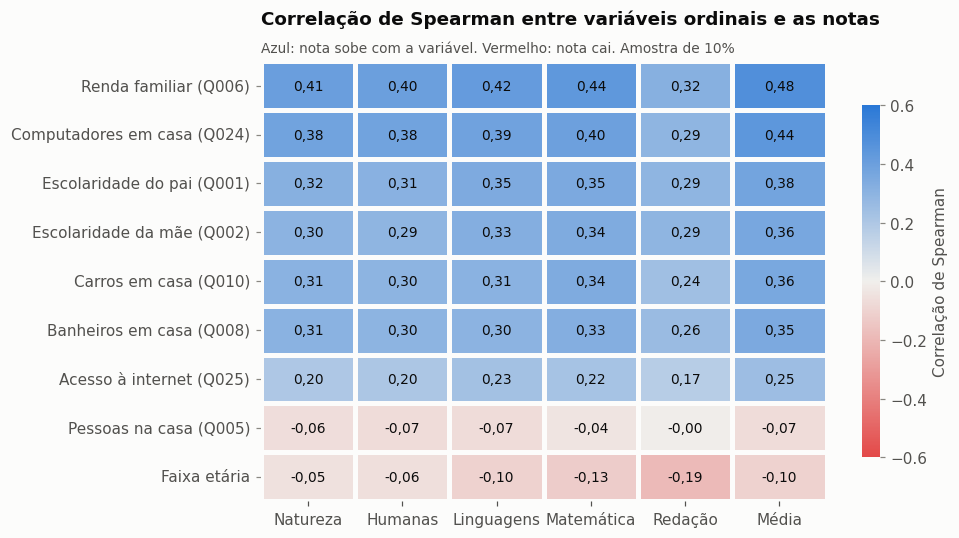

In [7]:
ordinal = pd.DataFrame({
    "Renda familiar (Q006)": amostra["q006"].map({c: i for i, c in enumerate("ABCDEFGHIJKLMNOPQ")}),
    "Escolaridade do pai (Q001)": amostra["q001"].map({c: i for i, c in enumerate("ABCDEFG")}),
    "Escolaridade da mãe (Q002)": amostra["q002"].map({c: i for i, c in enumerate("ABCDEFG")}),
    "Computadores em casa (Q024)": amostra["q024"].map({c: i for i, c in enumerate("ABCDE")}),
    "Acesso à internet (Q025)": amostra["q025"].map({"A": 0, "B": 1}),
    "Banheiros em casa (Q008)": amostra["q008"].map({c: i for i, c in enumerate("ABCDE")}),
    "Carros em casa (Q010)": amostra["q010"].map({c: i for i, c in enumerate("ABCDE")}),
    "Pessoas na casa (Q005)": amostra["q005"],
    "Faixa etária": amostra["tp_faixa_etaria"],
})
notas = amostra[list(PROVAS) + ["nu_nota_redacao", "media"]].rename(columns={
    "nu_nota_cn": "Natureza", "nu_nota_ch": "Humanas", "nu_nota_lc": "Linguagens",
    "nu_nota_mt": "Matemática", "nu_nota_redacao": "Redação", "media": "Média",
})
correlacao = pd.DataFrame({
    coluna_nota: ordinal.corrwith(notas[coluna_nota], method="spearman") for coluna_nota in notas
}).sort_values("Média", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(correlacao, annot=correlacao.map(lambda v: num(v, 2)), fmt="", cmap=DIVERGENTE,
            vmin=-0.6, vmax=0.6, linewidths=2, linecolor=SUPERFICIE,
            cbar_kws={"label": "Correlação de Spearman", "shrink": 0.8},
            annot_kws={"fontsize": 9, "color": TINTA}, ax=ax)
ax.grid(False)
ax.set_title("Correlação de Spearman entre variáveis ordinais e as notas")
subtitulo(ax, "Azul: nota sobe com a variável. Vermelho: nota cai. Amostra de 10%")
ax.tick_params(axis="x", labelrotation=0, colors=TINTA_SECUNDARIA)
ax.set_xlabel(""); ax.set_ylabel("")
salvar(fig, "05_correlacao_spearman")

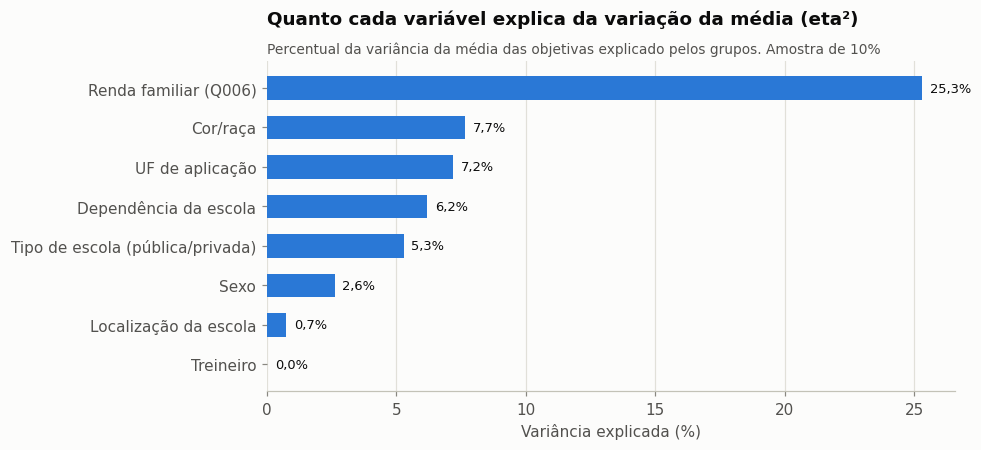

In [8]:
def eta_quadrado(grupo: pd.Series, valor: pd.Series) -> float:
    """Fração da variância de `valor` explicada pelas médias de `grupo`."""
    dados = pd.DataFrame({"g": grupo, "v": valor}).dropna()
    media_total = dados["v"].mean()
    entre = dados.groupby("g")["v"].agg(["count", "mean"])
    soma_entre = (entre["count"] * (entre["mean"] - media_total) ** 2).sum()
    soma_total = ((dados["v"] - media_total) ** 2).sum()
    return soma_entre / soma_total


categoricas = {
    "Tipo de escola (pública/privada)": amostra["ds_escola"],
    "Dependência da escola": amostra["ds_dependencia_adm_esc"],
    "UF de aplicação": amostra["sg_uf_prova"],
    "Cor/raça": amostra["ds_cor_raca"],
    "Treineiro": amostra["ds_treineiro"],
    "Sexo": amostra["ds_sexo"],
    "Localização da escola": amostra["ds_localizacao_esc"],
    "Renda familiar (Q006)": amostra["q006"],
}
eta = pd.Series({nome: eta_quadrado(serie, amostra["media"]) for nome, serie in categoricas.items()}) \
    .sort_values()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(eta.index, eta.values * 100, color=AZUL, height=0.6)
for i, valor in enumerate(eta.values):
    ax.text(valor * 100 + 0.3, i, f"{num(valor * 100)}%", va="center", fontsize=8.5, color=TINTA)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Quanto cada variável explica da variação da média (eta²)")
subtitulo(ax, "Percentual da variância da média das objetivas explicado pelos grupos. Amostra de 10%")
ax.set_xlabel("Variância explicada (%)")
salvar(fig, "06_eta_quadrado")

## 3. Dados da redação

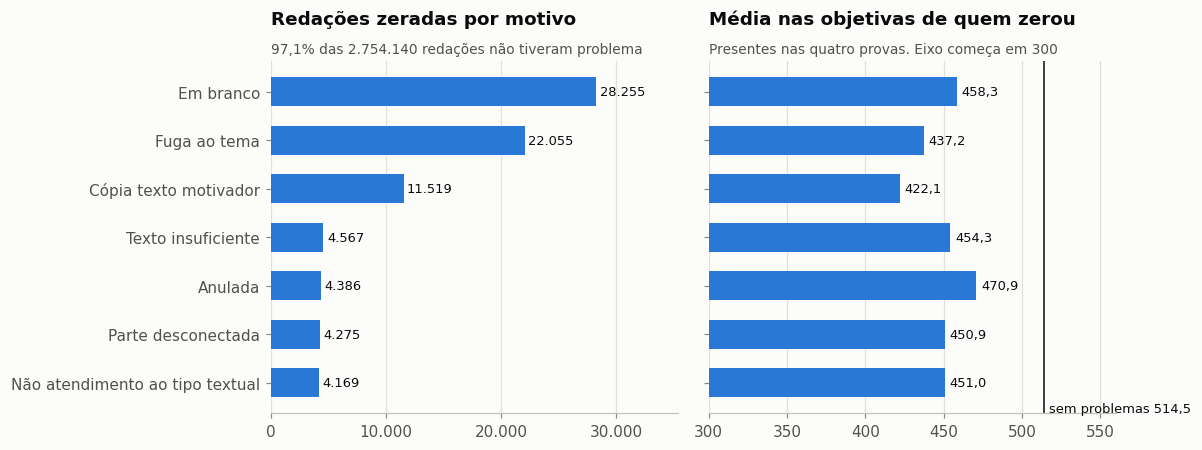

In [9]:
status = consultar("""
    SELECT s.ds_status_redacao AS status, COUNT(*) AS participantes,
           AVG(f.nu_media_objetivas) AS media_objetivas
    FROM fato_participacao f JOIN dim_status_redacao s ON s.tp_status_redacao = f.tp_status_redacao
    WHERE f.tp_status_redacao <> 0
    GROUP BY s.tp_status_redacao, s.ds_status_redacao
""")
total_redacoes = status["participantes"].sum()
sem_problemas = status.loc[status["status"] == "Sem problemas", "participantes"].iloc[0]
problemas = status[status["status"] != "Sem problemas"].sort_values("participantes")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
ax1.barh(problemas["status"], problemas["participantes"], color=AZUL, height=0.6)
for i, valor in enumerate(problemas["participantes"]):
    ax1.text(valor + 300, i, num(valor, 0), va="center", fontsize=8.5, color=TINTA)
ax1.set_title("Redações zeradas por motivo")
subtitulo(ax1, f"{num(100 * sem_problemas / total_redacoes)}% das {num(total_redacoes, 0)} redações não tiveram problema")
ax1.set_xlim(0, problemas["participantes"].max() * 1.25)
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.set_xticks([0, 10_000, 20_000, 30_000])
ax1.xaxis.set_major_formatter(lambda v, _: num(v, 0))
media_sem_problema = status.loc[status["status"] == "Sem problemas", "media_objetivas"].iloc[0]
ax2.barh(problemas["status"], problemas["media_objetivas"], color=AZUL, height=0.6)
ax2.axvline(media_sem_problema, color=TINTA, linewidth=1)
ax2.text(media_sem_problema + 3, -0.6, f"sem problemas {num(media_sem_problema)}", fontsize=8.5, color=TINTA)
for i, valor in enumerate(problemas["media_objetivas"]):
    ax2.text(valor + 3, i, num(valor), va="center", fontsize=8.5, color=TINTA)
ax2.set_xlim(300, 560)
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.set_title("Média nas objetivas de quem zerou")
subtitulo(ax2, "Presentes nas quatro provas. Eixo começa em 300")
salvar(fig, "07_redacao_status")

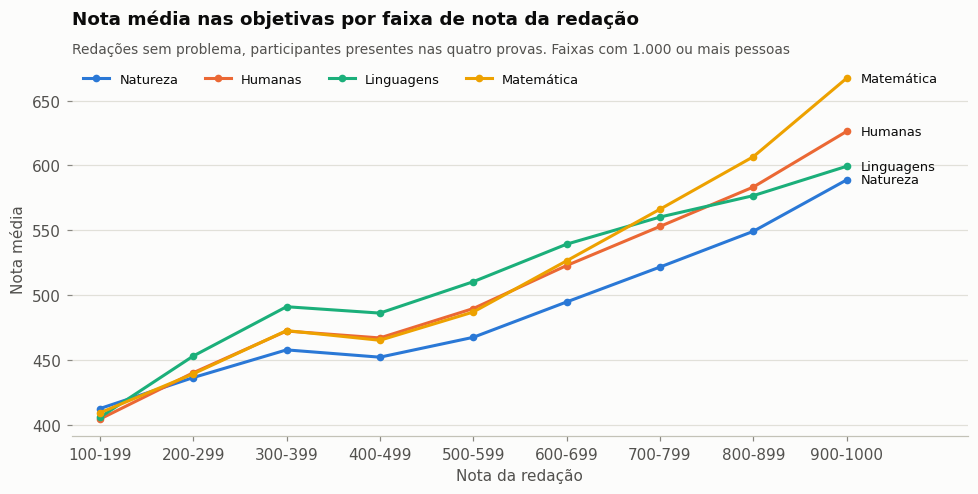

In [10]:
faixas = consultar("""
    SELECT LEAST(FLOOR(nu_nota_redacao / 100) * 100, 900) AS faixa, COUNT(*) AS participantes,
           AVG(nu_nota_cn) AS cn, AVG(nu_nota_ch) AS ch, AVG(nu_nota_lc) AS lc, AVG(nu_nota_mt) AS mt
    FROM fato_participacao
    WHERE nu_media_objetivas IS NOT NULL AND tp_status_redacao = 1
    GROUP BY faixa ORDER BY faixa
""")
faixas = faixas[faixas["participantes"] >= 1000]
fig, ax = plt.subplots(figsize=(9, 4.6))
for cor, (coluna, nome) in zip(SERIES, [("cn", "Natureza"), ("ch", "Humanas"), ("lc", "Linguagens"), ("mt", "Matemática")]):
    ax.plot(faixas["faixa"], faixas[coluna], color=cor, marker="o", markersize=4, label=nome)
    ax.text(faixas["faixa"].iloc[-1] + 15, faixas[coluna].iloc[-1], nome, va="center", fontsize=8.5, color=TINTA)
ax.set_xticks(faixas["faixa"], [f"{int(f)}-{int(f) + 99 if f < 900 else 1000}" for f in faixas["faixa"]])
ax.set_xlim(faixas["faixa"].min() - 30, faixas["faixa"].max() + 130)
ax.legend(loc="upper left", ncols=4, fontsize=8.5)
ax.set_title("Nota média nas objetivas por faixa de nota da redação")
subtitulo(ax, "Redações sem problema, participantes presentes nas quatro provas. Faixas com 1.000 ou mais pessoas")
ax.set_xlabel("Nota da redação")
ax.set_ylabel("Nota média")
salvar(fig, "08_objetivas_por_faixa_redacao")

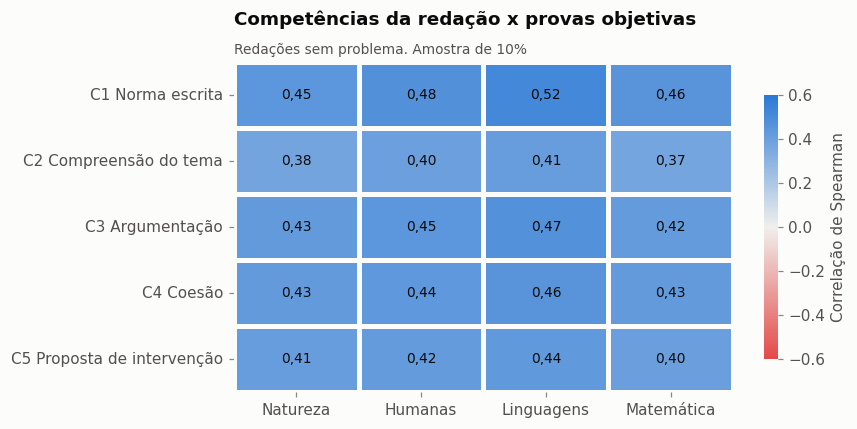

In [11]:
competencias = amostra[amostra["tp_status_redacao"] == 1][
    [f"nu_nota_comp{n}" for n in range(1, 6)] + list(PROVAS)
].corr(method="spearman").iloc[:5, 5:]
competencias.index = ["C1 Norma escrita", "C2 Compreensão do tema", "C3 Argumentação",
                      "C4 Coesão", "C5 Proposta de intervenção"]
competencias.columns = ["Natureza", "Humanas", "Linguagens", "Matemática"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(competencias, annot=competencias.map(lambda v: num(v, 2)), fmt="", cmap=DIVERGENTE,
            vmin=-0.6, vmax=0.6, linewidths=2, linecolor=SUPERFICIE,
            cbar_kws={"label": "Correlação de Spearman", "shrink": 0.8},
            annot_kws={"fontsize": 9, "color": TINTA}, ax=ax)
ax.grid(False)
ax.set_title("Competências da redação x provas objetivas")
subtitulo(ax, "Redações sem problema. Amostra de 10%")
ax.tick_params(axis="x", labelrotation=0)
ax.set_xlabel(""); ax.set_ylabel("")
salvar(fig, "09_competencias_x_provas")

## 4. Questionário socioeconômico

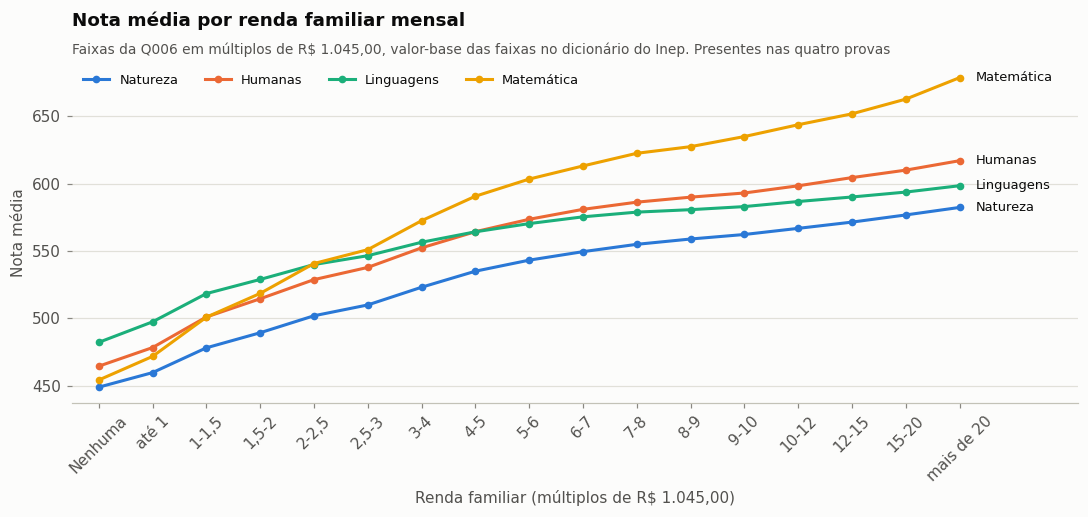

In [12]:
renda = consultar("""
    SELECT q.q006 AS faixa, COUNT(*) AS participantes,
           AVG(f.nu_nota_cn) AS cn, AVG(f.nu_nota_ch) AS ch, AVG(f.nu_nota_lc) AS lc,
           AVG(f.nu_nota_mt) AS mt, AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL AND q.q006 IS NOT NULL
    GROUP BY q.q006 ORDER BY q.q006
""")
rotulos_renda = ["Nenhuma", "até 1", "1-1,5", "1,5-2", "2-2,5", "2,5-3", "3-4", "4-5", "5-6",
                 "6-7", "7-8", "8-9", "9-10", "10-12", "12-15", "15-20", "mais de 20"]
fig, ax = plt.subplots(figsize=(10, 4.8))
for cor, (coluna, nome) in zip(SERIES, [("cn", "Natureza"), ("ch", "Humanas"), ("lc", "Linguagens"), ("mt", "Matemática")]):
    ax.plot(rotulos_renda, renda[coluna], color=cor, marker="o", markersize=4, label=nome)
    ax.text(16.3, renda[coluna].iloc[-1], nome, va="center", fontsize=8.5, color=TINTA)
ax.set_xlim(-0.5, 18.2)
ax.legend(loc="upper left", ncols=4, fontsize=8.5)
ax.tick_params(axis="x", labelrotation=45)
ax.set_title("Nota média por renda familiar mensal")
subtitulo(ax, "Faixas da Q006 em múltiplos de R$ 1.045,00, valor-base das faixas no dicionário do Inep. Presentes nas quatro provas")
ax.set_xlabel("Renda familiar (múltiplos de R$ 1.045,00)")
ax.set_ylabel("Nota média")
salvar(fig, "10_notas_por_renda")

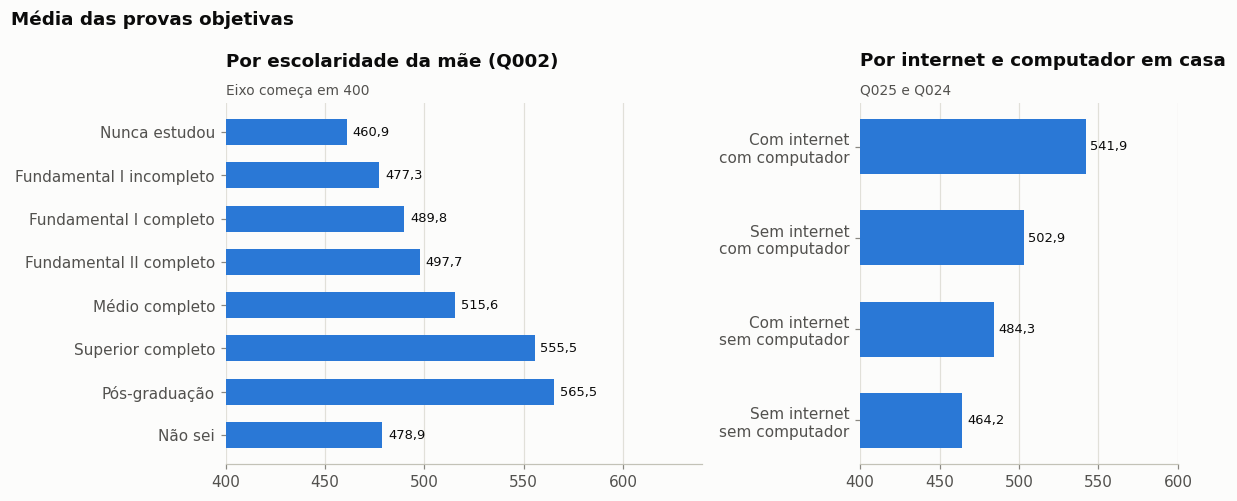

In [13]:
mae = consultar("""
    SELECT q.q002 AS resposta, COUNT(*) AS participantes, AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL AND q.q002 IS NOT NULL
    GROUP BY q.q002 ORDER BY q.q002
""")
rotulos_mae = {"A": "Nunca estudou", "B": "Fundamental I incompleto", "C": "Fundamental I completo",
               "D": "Fundamental II completo", "E": "Médio completo", "F": "Superior completo",
               "G": "Pós-graduação", "H": "Não sei"}
casa = consultar("""
    SELECT q.q025 AS internet, q.q024 > 'A' AS tem_computador, COUNT(*) AS participantes,
           AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    WHERE f.nu_media_objetivas IS NOT NULL AND q.q025 IS NOT NULL AND q.q024 IS NOT NULL
    GROUP BY q.q025, q.q024 > 'A'
""")
casa["grupo"] = casa.apply(lambda r: ("Com" if r["internet"] == "B" else "Sem") + " internet\n"
                           + ("com" if r["tem_computador"] else "sem") + " computador", axis=1)
casa = casa.sort_values("media")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax1.barh(mae["resposta"].map(rotulos_mae), mae["media"], color=AZUL, height=0.6)
for i, valor in enumerate(mae["media"]):
    ax1.text(valor + 3, i, num(valor), va="center", fontsize=8.5, color=TINTA)
ax1.set_xlim(400, 640)
ax1.invert_yaxis()
ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
ax1.set_title("Por escolaridade da mãe (Q002)")
subtitulo(ax1, "Eixo começa em 400")
ax2.barh(casa["grupo"], casa["media"], color=AZUL, height=0.6)
for i, (valor, n) in enumerate(zip(casa["media"], casa["participantes"])):
    ax2.text(valor + 3, i, num(valor), va="center", fontsize=8.5, color=TINTA)
ax2.set_xlim(400, 600)
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.set_title("Por internet e computador em casa")
subtitulo(ax2, "Q025 e Q024")
fig.suptitle("Média das provas objetivas", x=0.01, ha="left", fontsize=12, fontweight="bold")
salvar(fig, "11_media_mae_internet")

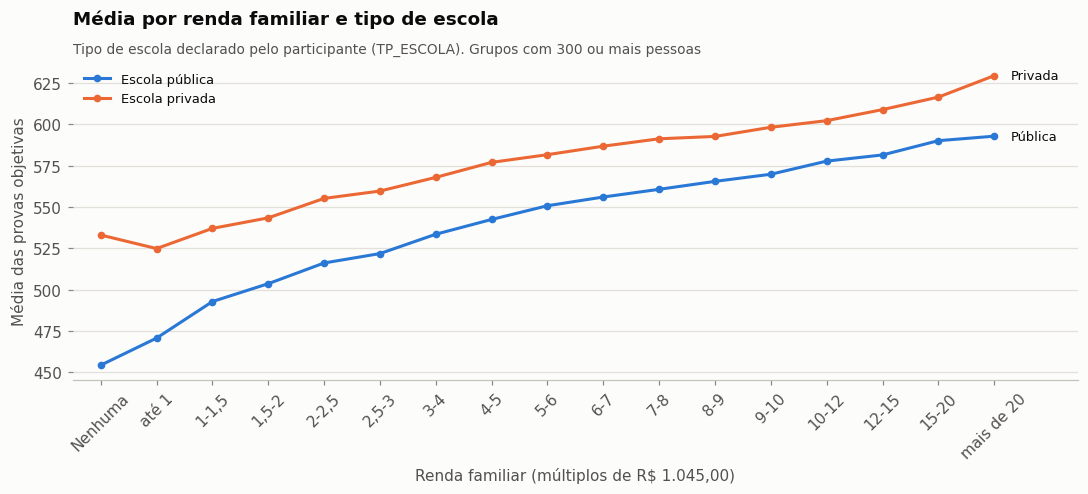

In [14]:
renda_escola = consultar("""
    SELECT q.q006 AS faixa, p.ds_escola AS escola, COUNT(*) AS participantes,
           AVG(f.nu_media_objetivas) AS media
    FROM fato_participacao f
    JOIN dim_questionario q ON q.nu_inscricao = f.nu_inscricao
    JOIN dim_perfil p ON p.sk_perfil = f.sk_perfil
    WHERE f.nu_media_objetivas IS NOT NULL AND p.ds_escola IN ('Pública', 'Privada')
    GROUP BY q.q006, p.ds_escola
    HAVING COUNT(*) >= 300
    ORDER BY q.q006
""")
fig, ax = plt.subplots(figsize=(10, 4.6))
for cor, escola in zip(SERIES, ["Pública", "Privada"]):
    dados = renda_escola[renda_escola["escola"] == escola]
    posicoes = dados["faixa"].map({c: i for i, c in enumerate("ABCDEFGHIJKLMNOPQ")})
    ax.plot(posicoes, dados["media"], color=cor, marker="o", markersize=4, label=f"Escola {escola.lower()}")
    ax.text(posicoes.iloc[-1] + 0.3, dados["media"].iloc[-1], escola, va="center", fontsize=8.5, color=TINTA)
ax.set_xticks(range(17), rotulos_renda, rotation=45)
ax.set_xlim(-0.5, 17.5)
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Média por renda familiar e tipo de escola")
subtitulo(ax, "Tipo de escola declarado pelo participante (TP_ESCOLA). Grupos com 300 ou mais pessoas")
ax.set_xlabel("Renda familiar (múltiplos de R$ 1.045,00)")
ax.set_ylabel("Média das provas objetivas")
salvar(fig, "12_renda_x_tipo_escola")